[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nattaponm/Teach_stormTracks_KKN_May2024_HID_doppler/blob/main/notebooks/01_reports_radar_geometry_day_selection.ipynb)

# บทที่ 01 — ฐานข้อมูลภัยพิบัติพบกับเรดาร์: จัดกลุ่มวันพายุเดือนพฤษภาคม 2567

**ชุดบทเรียน:** เส้นทางพายุ กายภาพเมฆ และความถี่เชิงพื้นที่ จากเรดาร์ขอนแก่น (KKN) กรมอุตุนิยมวิทยา เดือนพฤษภาคม 2567 (ค.ศ. 2024)

พฤษภาคมเป็นเดือนคาบเกี่ยวระหว่าง **ฤดูร้อน (pre-monsoon)** กับ **ฤดูฝน** กรมอุตุนิยมวิทยาประกาศเข้าสู่ฤดูฝนปี 2567 วันที่ 21 พฤษภาคม ก่อนหน้านั้นภาคอีสานมีพายุฤดูร้อนหลายระลอก ก่อนจะเปิดข้อมูลเรดาร์ เราเริ่มจากคำถามที่ง่ายที่สุดก่อน: **ในฐานข้อมูลความเสียหาย พายุเกิดวันไหน ที่ไหน รุนแรงแค่ไหน และเรดาร์มองเห็นหรือไม่**

### วัตถุประสงค์การเรียนรู้
เมื่อจบบทนี้ นิสิตจะสามารถ
1. ทำความสะอาดฐานข้อมูลภัยพิบัติที่บันทึกโดยมนุษย์ (รหัสข้อมูลขาด ชื่อสะกดต่าง แถวซ้ำ เวลาที่ระบุเป็นคำ) และแปลงเวลาท้องถิ่นเป็น UTC ให้ตรงกับเรดาร์
2. เชื่อมตาราง (attribute join) กับขอบเขตอำเภอ และคำนวณระยะ มุมทิศ สัดส่วนพื้นที่ในรัศมี 240 km ในระบบพิกัด Azimuthal Equidistant
3. อธิบายและคำนวณความสูงและความกว้างของลำคลื่นเรดาร์ตามระยะ (แบบจำลองโลก 4/3) และบอกข้อจำกัดของการตรวจพายุที่ระยะไกล
4. สร้างดัชนีความรุนแรงแบบ percentile-rank composite แบ่งระดับ น้อย/กลาง/มาก และทดสอบความไวต่อการเลือกน้ำหนัก
5. สรุปรายวัน จัดลำดับความสำคัญของวัน และผลิตแผนที่มาตรฐานวารสาร (DEM, วงระยะ, กริดพิกัด, มาตราส่วน, ทิศเหนือ, แผนที่ย่อ)

### ลำดับของชุดบทเรียน
| บท | เนื้อหา |
|---|---|
| **01** | ฐานข้อมูลภัยพิบัติ เรขาคณิตเรดาร์ จัดกลุ่มวัน ← *บทนี้* |
| 02 | จาก CAPPI สู่วัตถุพายุ: ภาพรวมรายวันทั้งเดือน |
| 03 | T-DaTing กับการทดลอง Δt = 15 / 10 / 5 นาที |
| 04 | Cloud footprint และ zonal statistics กับ Z, Doppler, dual-pol, HID |
| 05 | ภูมิประเทศ ระยะเรดาร์ และการตรวจสอบกับรายงานความเสียหาย |
| 06 | ความถี่เชิงพื้นที่ สถิติเชิงพื้นที่ และการสรุปรายตำบล/อำเภอ/จังหวัด |

> บทนี้ไม่ต้องใช้ข้อมูลเรดาร์ รันได้ทันที ผลลัพธ์ (ตารางรายงานที่ทำความสะอาดแล้ว และตารางรายวัน) ถูกใช้ต่อในบท 03–06

**ข้อมูลที่ใช้:** ฐานข้อมูลพายุภาคอีสาน 2567 (`data/ข้อมูลพายุอีสานปี2024.xlsx`), ขอบเขตการปกครอง OpenGISData-Thailand (CC BY 4.0), Copernicus DEM GLO-90 (© DLR/Airbus, ESA)

In [ ]:
# @title ⚙️ เตรียมสภาพแวดล้อม (รันครั้งเดียว — Colab จะ clone repo และติดตั้งไลบรารีให้)
import os, sys, subprocess
REPO = "Teach_stormTracks_KKN_May2024_HID_doppler"
if "google.colab" in sys.modules:
    if not os.path.isdir(f"/content/{REPO}"):
        subprocess.run(["git", "clone", "-q", f"https://github.com/nattaponm/{REPO}.git", f"/content/{REPO}"], check=True)
    os.chdir(f"/content/{REPO}")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) in ("notebooks", "prep"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("โฟลเดอร์ทำงาน:", os.getcwd())

โฟลเดอร์ทำงาน: /content/Teach_stormTracks_KKN_May2024_HID_doppler


In [ ]:
# @title 🔒 (เฉพาะผู้ดูแลข้อมูล) ดึงผลของ prep จาก Google Drive — นิสิตไม่ต้องแก้ ข้ามได้
ADMIN_SYNC = False          # ผู้ดูแล: True = ดึงพิกัดเรดาร์จริง/บัญชีไฟล์จาก P0 และเก็บผลบทนี้กลับเข้า Drive
if ADMIN_SYNC:
    from google.colab import drive
    drive.mount("/content/drive")
    from utils.config import load_settings
    from utils import sync
    OUT_ROOT = load_settings()["radar_data"]["drive_derived_root"]
    sync.pull(OUT_ROOT)

Mounted at /content/drive
sync.pull: /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/repo_mirror → /content/Teach_stormTracks_KKN_May2024_HID_doppler
  คัดลอก 6 ไฟล์ (2.2 MB): config/radar_site.json, data/inventory/daily_summary.csv, data/inventory/radar_files.csv, data/inventory/radar_inventory.csv, data/inventory/scan_strategies.csv, data/inventory/segments.csv


In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from shapely.geometry import Point
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

from utils.config import load_settings, repo_path
from utils import reports as R, geo as G, maps as M

s = load_settings()
M.setup_style()
pd.set_option("display.max_columns", 40, "display.width", 200)
print("เรดาร์:", s["radar"]["name"], s["radar"]["lat"], s["radar"]["lon"], "| ที่มาพิกัด:", s["radar"]["site_source"])

เรดาร์: KKN 16.4625 102.78588 | ที่มาพิกัด: uf_header


## 1. อ่านฐานข้อมูลและสำรวจโครงสร้าง

ฐานข้อมูลนี้รวบรวมจากรายงานของกรมป้องกันและบรรเทาสาธารณภัย (ปภ.) และเพจข่าวของจังหวัด **หนึ่งแถว = หนึ่งอำเภอในหนึ่งวัน** ไม่ใช่หนึ่งพายุ พายุลูกเดียวอาจสร้างความเสียหายหลายอำเภอ และอำเภอเดียวอาจโดนพายุหลายลูกในวันเดียว ข้อนี้สำคัญมากเมื่อเราจับคู่กับเส้นทางพายุในบท 05

ข้อมูลเชิงสังคมลักษณะนี้มี **อคติจากการรายงาน (reporting bias)**: พื้นที่ที่มีคนอยู่มากหรือมีเพจข่าวที่ตื่นตัวจะถูกบันทึกมากกว่า ความเสียหายจึงสะท้อนทั้งความรุนแรงของพายุ **และ** ความเปราะบางของพื้นที่ (exposure)

In [ ]:
raw = R.read_reports(s)
print("ขนาดตาราง:", raw.shape)
print(raw.groupby(["year_be", "month"]).size().rename("จำนวนแถว").to_string())
raw.head(3)

ขนาดตาราง: (191, 35)
year_be  month
2566     5         1
2567     2        10
         3        47
         4        53
         5        76
2568     5         4


,rec_id,day,month,year_be,t_start_raw,t_end_raw,province,district,จังหวัด_ย่อ,อำเภอ_ย่อ,count,hazard_type,wind,rain,hail,hail_size,lightning,ดินไลด์,flood,น้ำป่าไหลหลาก,n_tambon,n_village,houses,injured,dead,สัตว์เลี้ยงบาดเจ็บ,livestock_dead,other_property,note,ลิงก์ข่าว_ปภ,แหล่งข่าว,ลิงก์ข่าว_จากเพจ,แหล่งข่าว.1,ลิงก์ข่าว_จากเพจ.1,แหล่งข่าว.2
0,1,6,5,2567,15.3,-,กาฬสินธุ์,นาคู,จ.กาฬสินธุ์,อ.นาคู,1,วาตภัย/พายุฤดูร้อน/ลมกระโชกแรง/ฟ้าผ่า,y,y,n,ไม่เกิดลูกเห็บ,y,n,n,n,3,8,57,0,0,0,0,1,วันที่ 6 พฤษภาคม 2567 เวลาประมาณ 15.30 น. ได้เ...,https://dpmreporter.disaster.go.th/portal/disa...,ปภ.,NaN,NaN,NaN,NaN
1,2,5,5,2567,ช่วงบ่าย,-,กาฬสินธุ์,สมเด็จ,จ.กาฬสินธุ์,อ.สมเด็จ,1,วาตภัย/พายุฤดูร้อน/ลมกระโชกแรง,y,y,n,ไม่เกิดลูกเห็บ,n,n,n,n,1,9999,108,0,0,0,0,0,เมื่อบ่ายวันที่ 5 พฤษภาคม 2567 ที่ผ่านมาได้เกิ...,ไม่พบในปภ.,ไม่พบในปภ.,https://kalasin.prd.go.th/th/content/category/...,สำนักงานประชาสัมพันธ์จังหวัดกาฬสินธุ์,NaN,NaN
2,3,5,5,2567,ช่วงบ่าย,-,กาฬสินธุ์,สามชัย,จ.กาฬสินธุ์,อ.สามชัย,1,วาตภัย/พายุฤดูร้อน/ลมกระโชกแรง,y,y,n,ไม่เกิดลูกเห็บ,n,n,n,n,1,1,32,0,0,0,0,0,เมื่อบ่ายวันที่ 5 พฤษภาคม 2567 ที่ผ่านมาได้เกิ...,ไม่พบในปภ.,ไม่พบในปภ.,https://kalasin.prd.go.th/th/content/category/...,สำนักงานประชาสัมพันธ์จังหวัดกาฬสินธุ์,NaN,NaN


## 2. ทำความสะอาดข้อมูล

ปัญหาที่พบในไฟล์นี้ และวิธีแก้ใน `utils/reports.py`

| ปัญหา | ตัวอย่าง | วิธีจัดการ |
|---|---|---|
| รหัสข้อมูลขาด | `9999` ในจำนวนหมู่บ้าน บ้านเสียหาย | แปลงเป็น `NaN` — ถ้าลืม ผลรวมบ้านเสียหายจะผิดหลายหมื่นหลัง |
| ชื่อสะกดต่าง / ช่องว่าง | `นคราชสีมา`, `พรรณนานิคม`, `"เมืองเลย "` | ตาราง alias ใน `config/settings.yaml` |
| แถวซ้ำ | รายงานเดียวกันบันทึกสองครั้ง | ตัดโดยเทียบวัน อำเภอ เวลา และตัวเลขความเสียหาย |
| ปีพุทธศักราช | `2567` | ค.ศ. = พ.ศ. − 543 |
| เวลาเป็นทศนิยม | `17.3` = 17:30 น., `16.4` = 16:40 น. | อ่านเป็น ชั่วโมง.นาที |
| เวลาเป็นคำ | `ช่วงเย็น`, `ช่วงบ่าย`, `-` | แปลงเป็นหน้าต่างเวลา |

**การแปลงเวลา** เรดาร์บันทึกเวลาเป็น UTC แต่รายงานใช้เวลาประเทศไทย

$$t_{\mathrm{UTC}} = t_{\mathrm{local}} - 7\ \mathrm{h}$$

รายงานที่บอกเวลา (เช่น 17:30 น.) เป็นเวลาที่ชาวบ้านจำได้ ไม่ใช่เวลาที่วัดด้วยเครื่องมือ เราจึงไม่ใช้เป็นจุดเวลาเดียว แต่ใช้ **หน้าต่างเวลา** $[t-60,\ t+60]$ นาที ส่วนรายงานแบบคำใช้ช่วงตามตาราง เช่น ช่วงเย็น = 16–19 น.

In [ ]:
rep, log = R.clean_reports(raw, s)
print(f"รายงานเดือนพฤษภาคมหลังทำความสะอาด: {len(rep)} แถว")
log

รายงานเดือนพฤษภาคมหลังทำความสะอาด: 74 แถว


,ขั้นตอน,รายละเอียด,จำนวน
0,เลือกเดือน,2024-05,76
1,แก้ชื่อ,นคราชสีมา/ปากช่อง → นครราชสีมา/ปากช่อง,1
2,แก้ชื่อ,นคราชสีมา/ปากช่อง → นครราชสีมา/ปากช่อง,1
3,แก้ชื่อ,สกลนคร/พรรณนานิคม → สกลนคร/พรรณานิคม,1
4,9999 → NaN,n_tambon,16
5,9999 → NaN,n_village,22
6,9999 → NaN,houses,14
7,9999 → NaN,injured,1
8,ตัดแถวซ้ำ,ลำดับ 71: 6/5 มุกดาหาร/เมืองมุกดาหาร,1
9,ตัดแถวซ้ำ,ลำดับ 159: 13/5 หนองบัวลำภู/ศรีบุญเรือง,1


In [ ]:
# ชนิดของเวลาที่ระบุในรายงาน
kind_th = {"exact": "ระบุเวลา", "period": "ระบุเป็นช่วง (คำ)", "unknown": "ไม่ระบุ"}
print(rep["time_kind"].map(kind_th).value_counts().to_string())
rep[["report_id", "date", "t_start_raw", "time_kind", "win_start_utc", "win_end_utc",
     "province", "district", "houses", "casualties", "hail"]].head(8)

time_kind
ระบุเวลา             46
ระบุเป็นช่วง (คำ)    20
ไม่ระบุ               8


,report_id,date,t_start_raw,time_kind,win_start_utc,win_end_utc,province,district,houses,casualties,hail
0,R0501-01,2024-05-01,19,exact,2024-05-01 11:00:00,2024-05-01 13:00:00,สกลนคร,พรรณานิคม,NaN,0.0,False
1,R0501-02,2024-05-01,-,unknown,2024-04-30 17:00:00,2024-05-01 17:00:00,สกลนคร,พังโคน,1.0,0.0,False
2,R0501-03,2024-05-01,19,exact,2024-05-01 11:00:00,2024-05-01 13:00:00,สกลนคร,วานรนิวาส,NaN,0.0,False
3,R0501-04,2024-05-01,19,exact,2024-05-01 11:00:00,2024-05-01 13:00:00,สกลนคร,สว่างแดนดิน,1.0,1.0,False
4,R0501-05,2024-05-01,15.3,exact,2024-05-01 07:30:00,2024-05-01 09:30:00,หนองบัวลำภู,เมืองหนองบัวลำภู,70.0,0.0,False
5,R0502-01,2024-05-02,-,unknown,2024-05-01 17:00:00,2024-05-02 17:00:00,สกลนคร,อากาศอำนวย,1.0,0.0,False
6,R0503-01,2024-05-03,14,exact,2024-05-03 06:00:00,2024-05-03 08:00:00,ขอนแก่น,บ้านไผ่,NaN,0.0,False
7,R0503-02,2024-05-03,ช่วงเย็น,period,2024-05-03 09:00:00,2024-05-03 12:00:00,ขอนแก่น,เมืองขอนแก่น,1.0,1.0,False


## 3. เชื่อมรายงานกับขอบเขตอำเภอ

รายงานระบุตำแหน่งแค่ **ระดับอำเภอ** ความคลาดเคลื่อนเชิงพื้นที่จึงเท่ากับขนาดอำเภอ (ราว 10–40 km) เราจะใช้ **polygon ของอำเภอ** แทนจุดเดียว เพื่อให้บท 05 จับคู่ได้ว่า "เส้นทางพายุผ่านอำเภอนี้หรือไม่" อย่างถูกต้อง

ระบบพิกัดที่ใช้ตลอดชุดบทเรียนคือ **Azimuthal Equidistant (AEQD)** ศูนย์กลางที่เรดาร์ ในระบบนี้ระยะจากเรดาร์ไปยังทุกจุดถูกต้อง วงระยะ 240 km จึงเป็นวงกลมจริง

In [ ]:
dist = G.load_admin("district", s)            # อำเภอในรัศมี 300 km (AEQD, เมตร)
gdf = dist.merge(rep, left_on=["pro_th", "amp_th"], right_on=["province", "district"], how="right")
gdf = gpd.GeoDataFrame(gdf, geometry="geometry", crs=dist.crs)
nomatch = gdf[gdf.geometry.isna()]
print("รายงานที่หาอำเภอไม่พบ:", len(nomatch))
if len(nomatch):
    display(nomatch[["report_id", "province", "district"]])
gdf = gdf[gdf.geometry.notna()].copy()

รายงานที่หาอำเภอไม่พบ: 0


## 4. เรขาคณิตของเรดาร์: ระยะ ทิศ และความสูงลำคลื่น

สำหรับแต่ละอำเภอ เราคำนวณ

- ระยะและมุมทิศของจุดศูนย์กลาง (centroid): $r = \sqrt{x^2+y^2}$, $\ \phi = \operatorname{atan2}(x, y)$ (องศาจากทิศเหนือ)
- ระยะใกล้สุด/ไกลสุดของขอบอำเภอ และ **สัดส่วนพื้นที่ที่อยู่ในรัศมี 240 km**

**ความสูงลำคลื่น** คลื่นเรดาร์เดินทางเป็นเส้นโค้งเพราะการหักเหในบรรยากาศ แบบจำลองมาตรฐานแทนด้วยโลกที่มีรัศมีใหญ่ขึ้น $k_e R$ เมื่อ $k_e = 4/3$ (Doviak & Zrnić, 1993)

$$h(r,\theta) = \sqrt{r^2 + (k_eR)^2 + 2\,r\,k_eR\sin\theta}\; - k_eR + h_0$$

และความกว้างของลำคลื่น $\ w \approx r\,\Delta\theta$ ที่ $\Delta\theta = 1^\circ$

ที่ระยะ 200 km มุมยกต่ำสุด 0.5° ลำคลื่นอยู่สูงราว 4 km และกว้างราว 3.5 km จึงมองไม่เห็นลมกระโชกใกล้พื้น (downburst) และเฉลี่ยรายละเอียดของพายุลูกเล็ก ข้อนี้คือเหตุผลที่เราแบ่งกลุ่มระยะ 0–100, 100–160 และ 160–240 km

In [ ]:
rad = s["radar"]
c = gdf.geometry.centroid
gdf["r_km"], gdf["az_deg"] = G.range_azimuth(c.x, c.y)
gdf["r_min_km"] = gdf.geometry.distance(Point(0, 0)) / 1e3
gdf["r_max_km"] = gdf.geometry.apply(lambda g: np.hypot(*np.asarray(g.convex_hull.exterior.coords).T).max() / 1e3)
disk = G.coverage_disk(s).geometry.iloc[0]
gdf["frac_in_240"] = (gdf.geometry.intersection(disk).area / gdf.geometry.area).round(3)
gdf["coverage"] = np.select([gdf.frac_in_240 >= 0.99, gdf.frac_in_240 > 0], ["ทั้งอำเภอ", "บางส่วน"], "นอกรัศมี")
gdf["beam_h_km"] = G.beam_height_km(gdf.r_km, rad["lowest_elev_deg"], rad["alt_m"])
gdf["beam_w_km"] = G.beam_width_km(gdf.r_km, rad["beamwidth_deg"])
bins = s["geometry"]["range_bins_km"]
gdf["range_bin"] = pd.cut(gdf.r_km, bins + [np.inf], labels=[f"{a}–{b}" for a, b in zip(bins[:-1], bins[1:])] + [f">{bins[-1]}"])

# ความสูงภูมิประเทศเฉลี่ยและสูงสุดในอำเภอ (zonal statistics จาก DEM 1 km)
dem = G.load_dem(s)
zs = G.zonal_stats(*dem, gdf.geometry.values, funcs=("mean", "max"))
gdf["elev_mean_m"], gdf["elev_max_m"] = zs["mean"].values, zs["max"].values

print(gdf["coverage"].value_counts().to_string())
gdf[["report_id", "province", "district", "r_km", "az_deg", "frac_in_240", "coverage", "beam_h_km", "beam_w_km", "range_bin"]].sort_values("r_km").round(1).tail(8)

coverage
ทั้งอำเภอ    63
บางส่วน       7
นอกรัศมี      4


,report_id,province,district,r_km,az_deg,frac_in_240,coverage,beam_h_km,beam_w_km,range_bin
60,R0506-07,อำนาจเจริญ,พนา,237.9,111.3,0.7,บางส่วน,5.6,4.2,160–240
42,R0505-05,นครราชสีมา,ครบุรี,238.5,195.0,0.5,บางส่วน,5.6,4.2,160–240
72,R0522-01,นครราชสีมา,ปากช่อง,248.8,215.1,0.3,บางส่วน,6.0,4.3,>240
71,R0521-01,นครราชสีมา,ปากช่อง,248.8,215.1,0.3,บางส่วน,6.0,4.3,>240
53,R0505-16,อุบลราชธานี,วารินชำราบ,267.1,123.5,0.0,นอกรัศมี,6.7,4.7,>240
62,R0510-01,อุบลราชธานี,วารินชำราบ,267.1,123.5,0.0,นอกรัศมี,6.7,4.7,>240
63,R0510-02,อุบลราชธานี,สำโรง,270.3,127.1,0.0,นอกรัศมี,6.9,4.7,>240
70,R0520-03,อุบลราชธานี,สิรินธร,320.9,117.4,0.0,นอกรัศมี,9.1,5.6,>240


บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb01_beam_height.png / .pdf


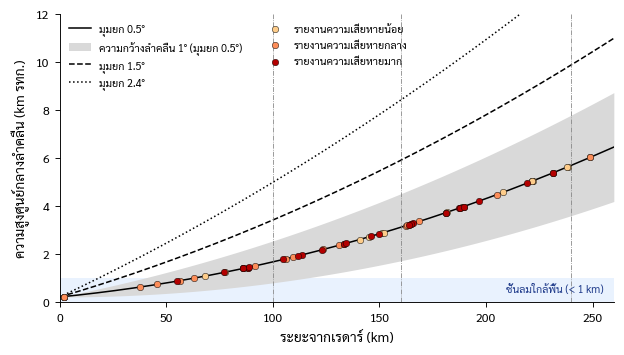

In [ ]:
# รูป: ความสูงและความกว้างลำคลื่นตามระยะ เทียบกับตำแหน่งรายงาน
r = np.linspace(0, 260, 300)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for el, ls in [(0.5, "-"), (1.5, "--"), (2.4, ":")]:
    h = G.beam_height_km(r, el, rad["alt_m"])
    w = G.beam_width_km(r, rad["beamwidth_deg"])
    ax.plot(r, h, color="k", ls=ls, lw=1, label=f"มุมยก {el}°")
    if el == 0.5:
        ax.fill_between(r, h - w / 2, h + w / 2, color="0.85", lw=0, label="ความกว้างลำคลื่น 1° (มุมยก 0.5°)")
tier_tmp = R.tier_labels(R.severity_index(gdf)[0])
for t, col in M.TIER_COLORS.items():
    m = tier_tmp == t
    ax.scatter(gdf.r_km[m], gdf.beam_h_km[m], s=18, color=col, ec="k", lw=0.3, zorder=5, label=f"รายงานความเสียหาย{t}")
for b in bins[1:]:
    ax.axvline(b, color="0.5", lw=0.5, ls="-.")
ax.axhspan(0, 1, color="#dbeafe", alpha=0.6, lw=0, zorder=0)
ax.text(255, 0.5, "ชั้นลมใกล้พื้น (< 1 km)", fontsize=7, va="center", ha="right", color="#1e3a8a")
ax.set(xlabel="ระยะจากเรดาร์ (km)", ylabel="ความสูงศูนย์กลางลำคลื่น (km รทก.)", xlim=(0, 260), ylim=(0, 12))
ax.legend(loc="upper left", frameon=False, ncol=2, fontsize=7)
M.savefig(fig, "nb01_beam_height")
plt.show()

## 5. ดัชนีความรุนแรงและการแบ่งระดับ น้อย / กลาง / มาก

ตัวชี้วัดความเสียหายมีหน่วยต่างกัน (หลังคาเรือน คน จำนวนตำบล มี/ไม่มีลูกเห็บ) และกระจายเบ้มาก (บางอำเภอบ้านเสียหาย 1,400 หลัง ส่วนใหญ่ไม่ถึง 50) ถ้าบวกกันตรง ๆ ตัวชี้วัดเดียวจะครอบงำ เราจึงแปลงแต่ละตัวเป็น **ลำดับเปอร์เซ็นไทล์** ก่อนเฉลี่ย

$$S_i = \frac{\sum_k w_k\,P_k(x_{ik})}{\sum_k w_k}, \qquad P_k(x) = \frac{\operatorname{rank}(x)}{n} \in (0, 1]$$

โดย $k$ คือ บ้านเสียหาย จำนวนตำบล จำนวนหมู่บ้าน ผู้บาดเจ็บ+เสียชีวิต และลูกเห็บ ค่าที่หายไปไม่ถูกนับในตัวหาร จากนั้นแบ่ง 3 ระดับด้วย **tertile** (ระดับละประมาณหนึ่งในสาม)

จำนวนตำบลและหมู่บ้านใช้เป็นตัวแทน **ความกว้างของพื้นที่เสียหาย** ส่วนบ้านเสียหายและผู้บาดเจ็บเป็นตัวแทน **ความหนักของความเสียหาย**

> ข้อควรระวัง: ระดับนี้เป็น **ระดับเชิงเปรียบเทียบภายในเดือนนี้** ไม่ใช่มาตรวัดความรุนแรงทางอุตุนิยมวิทยา (เช่น ความเร็วลม)

In [ ]:
gdf["S"], P = R.severity_index(gdf)
gdf["tier"] = R.tier_labels(gdf["S"])
print(gdf["tier"].value_counts().reindex(["น้อย", "กลาง", "มาก"]).to_string())
gdf.sort_values("S", ascending=False)[["report_id", "date", "province", "district", "houses", "n_tambon",
                                        "n_village", "casualties", "hail", "S", "tier"]].head(10).round(2)

tier
น้อย    25
กลาง    24
มาก     25


,report_id,date,province,district,houses,n_tambon,n_village,casualties,hail,S,tier
21,R0503-16,2024-05-03,หนองบัวลำภู,สุวรรณคูหา,807.0,3.0,20.0,1.0,False,0.86,มาก
19,R0503-14,2024-05-03,หนองบัวลำภู,นากลาง,1106.0,4.0,28.0,0.0,False,0.77,มาก
49,R0505-12,2024-05-05,สกลนคร,วานรนิวาส,31.0,2.0,2.0,0.0,True,0.72,มาก
54,R0506-01,2024-05-06,กาฬสินธุ์,นาคู,57.0,3.0,8.0,0.0,False,0.72,มาก
4,R0501-05,2024-05-01,หนองบัวลำภู,เมืองหนองบัวลำภู,70.0,2.0,16.0,0.0,False,0.71,มาก
56,R0506-03,2024-05-06,มหาสารคาม,วาปีปทุม,19.0,5.0,8.0,0.0,False,0.71,มาก
32,R0503-27,2024-05-03,เลย,เมืองเลย,NaN,NaN,NaN,0.0,True,0.70,มาก
25,R0503-20,2024-05-03,เลย,นาด้วง,NaN,NaN,NaN,0.0,True,0.70,มาก
30,R0503-25,2024-05-03,เลย,หนองหิน,NaN,NaN,NaN,0.0,True,0.70,มาก
31,R0503-26,2024-05-03,เลย,เชียงคาน,NaN,NaN,NaN,0.0,True,0.70,มาก


In [ ]:
# ความไวต่อน้ำหนัก: ถ้าเปลี่ยนวิธีให้น้ำหนัก อันดับรายงานเปลี่ยนมากไหม
schemes = {
    "เท่ากัน": None,
    "เน้นบ้านเสียหาย": {"houses": 3, "n_tambon": 1, "n_village": 1, "casualties": 1, "hail": 1},
    "เน้นความกว้าง": {"houses": 1, "n_tambon": 3, "n_village": 3, "casualties": 1, "hail": 1},
    "เน้นอันตรายต่อชีวิต": {"houses": 1, "n_tambon": 1, "n_village": 1, "casualties": 3, "hail": 2},
}
Ss = pd.DataFrame({k: R.severity_index(gdf, w)[0] for k, w in schemes.items()})
rho = Ss.corr(method="spearman").round(2)
changed = {k: int((R.tier_labels(Ss[k]) != gdf["tier"]).sum()) for k in schemes}
print("จำนวนรายงานที่เปลี่ยนระดับเทียบกับน้ำหนักเท่ากัน:", changed)
rho

จำนวนรายงานที่เปลี่ยนระดับเทียบกับน้ำหนักเท่ากัน: {'เท่ากัน': 0, 'เน้นบ้านเสียหาย': 16, 'เน้นความกว้าง': 18, 'เน้นอันตรายต่อชีวิต': 13}


,เท่ากัน,เน้นบ้านเสียหาย,เน้นความกว้าง,เน้นอันตรายต่อชีวิต
เท่ากัน,1.00,0.95,0.97,0.92
เน้นบ้านเสียหาย,0.95,1.00,0.89,0.83
เน้นความกว้าง,0.97,0.89,1.00,0.86
เน้นอันตรายต่อชีวิต,0.92,0.83,0.86,1.00


## 6. สรุปรายวันและจัดลำดับความสำคัญ

หน่วยที่ **เป็นอิสระต่อกัน** จริงในงานนี้คือ "วัน" ไม่ใช่รายงานหรือเส้นทางพายุ เพราะพายุในวันเดียวกันเกิดจากสภาพบรรยากาศชุดเดียวกัน (CAPE, ลมเฉือน, ความชื้น) เราจึงสรุปเป็นรายวัน

- **ขอบเขตการกระจาย (spread)** = ระยะห่างสูงสุดระหว่างจุดศูนย์กลางอำเภอที่เสียหายในวันนั้น $\max_{i,j}\lVert \mathbf{c}_i-\mathbf{c}_j\rVert$ — บอกว่าพายุวันนั้นกระจายกว้างแค่ไหน
- **คะแนนวัน** $D = \sum_{i \in \text{ในรัศมี}} S_i$ — รวมความรุนแรงเฉพาะรายงานที่เรดาร์มองเห็น เพราะเราต้องการวันที่ใช้ข้อมูลเรดาร์ศึกษาได้
- **ช่วงของเดือน**: ระลอกพายุฤดูร้อน (1–9), ปลายฤดูร้อน (10–20), ต้นฤดูฝน (21–31 พ.ค.)

In [ ]:
gdf["phase"] = R.assign_phase(gdf["date"], s)
gdf["in_range"] = gdf["coverage"] != "นอกรัศมี"

def day_summary(g):
    cx, cy = g.geometry.centroid.x / 1e3, g.geometry.centroid.y / 1e3
    xy = np.c_[cx, cy]
    return pd.Series({
        "phase": g["phase"].iloc[0],
        "n_reports": len(g),
        "n_provinces": g["province"].nunique(),
        "n_in_range": int(g["in_range"].sum()),
        "houses": g["houses"].sum(min_count=1),
        "casualties": g["casualties"].sum(min_count=1),
        "hail_reports": int(g["hail"].sum()),
        "n_tier_high": int((g["tier"] == "มาก").sum()),
        "spread_km": pdist(xy).max() if len(g) > 1 else 0.0,
        "median_r_km": g["r_km"].median(),
        "D_in_range": g.loc[g["in_range"], "S"].sum(),
        "first_local": g["t_report_local"].min(),
        "last_local": g["t_report_local"].max(),
    })

day = gdf.groupby("date").apply(day_summary, include_groups=False)
day["priority"] = day["D_in_range"].rank(ascending=False, method="min").astype(int)
day["day_tier"] = R.tier_labels(day["D_in_range"])
day = day.sort_values("priority")
day.round(1)

,phase,n_reports,n_provinces,n_in_range,houses,casualties,hail_reports,n_tier_high,spread_km,median_r_km,D_in_range,first_local,last_local,priority,day_tier
date,,,,,,,,,,,,,,,
2024-05-03,outbreak,27,8,27,2528.0,5.0,8,13,443.4,146.1,15.3,2024-05-03 14:00:00,2024-05-03 21:00:00,1,มาก
2024-05-05,outbreak,16,8,15,472.0,0.0,1,4,394.7,184.6,7.6,2024-05-05 14:00:00,2024-05-05 19:00:00,2,มาก
2024-05-06,outbreak,8,5,8,369.0,2.0,0,5,194.7,189.6,4.5,2024-05-06 15:30:00,2024-05-06 18:30:00,3,มาก
2024-05-01,outbreak,5,2,5,72.0,1.0,0,1,159.9,145.1,2.4,2024-05-01 15:30:00,2024-05-01 19:00:00,4,มาก
2024-05-04,outbreak,5,3,5,84.0,0.0,3,1,162.9,86.2,2.3,2024-05-04 16:00:00,2024-05-04 17:00:00,5,มาก
2024-05-13,late_pre,3,3,3,4.0,0.0,0,1,105.2,133.5,1.5,2024-05-13 14:30:00,2024-05-13 17:30:00,6,กลาง
2024-05-20,late_pre,3,2,2,3.0,1.0,0,0,102.7,221.6,0.7,2024-05-20 16:00:00,2024-05-20 16:00:00,7,กลาง
2024-05-22,rainy,1,1,1,NaN,0.0,0,0,0.0,248.8,0.6,NaT,NaT,8,กลาง
2024-05-19,late_pre,1,1,1,7.0,0.0,0,0,0.0,231.4,0.5,2024-05-19 16:30:00,2024-05-19 16:30:00,9,กลาง


In [ ]:
# วันในเดือนที่ไม่มีรายงานเลย — ผู้สมัครเป็น "วันควบคุม" (มีพายุแต่ไม่มีความเสียหาย?) ตรวจอีกครั้งด้วยข้อมูลเรดาร์ใน P0/บท 02
may = pd.date_range("2024-05-01", "2024-05-31", freq="D")
no_report = [d for d in may if d not in day.index]
print(f"วันที่มีรายงาน {len(day)} วัน | วันที่ไม่มีรายงาน {len(no_report)} วัน:")
print(", ".join(d.strftime("%d") for d in no_report))

วันที่มีรายงาน 13 วัน | วันที่ไม่มีรายงาน 18 วัน:
07, 08, 09, 11, 12, 14, 15, 16, 17, 18, 23, 24, 25, 26, 27, 28, 29, 30


In [ ]:
# ถ้ามีผลสำรวจข้อมูลเรดาร์จาก prep/P0 แล้ว: ตรวจว่าเรดาร์มีข้อมูลในหน้าต่างเวลาของแต่ละรายงานหรือไม่
inv_path = repo_path("data", "inventory", "radar_inventory.csv")
if inv_path.exists():
    inv = pd.read_csv(inv_path, parse_dates=["slot_utc"])
    ok_slots = inv.loc[inv["status"].isin(["ok", "offset"]), "slot_utc"].sort_values().values
    def n_scans(r):
        return int(((ok_slots >= np.datetime64(r.win_start_utc)) & (ok_slots <= np.datetime64(r.win_end_utc))).sum())
    gdf["n_scans_in_window"] = gdf.apply(n_scans, axis=1)
    gdf["radar_verifiable"] = gdf["in_range"] & (gdf["n_scans_in_window"] > 0)
    print(gdf.groupby("coverage")["radar_verifiable"].agg(["sum", "count"]))
else:
    gdf["n_scans_in_window"] = np.nan
    gdf["radar_verifiable"] = gdf["in_range"]
    print("ยังไม่มีผลสำรวจข้อมูลเรดาร์ (prep/P0) — ใช้เฉพาะเงื่อนไขรัศมีไปก่อน")

           sum  count
coverage             
ทั้งอำเภอ   63     63
นอกรัศมี     0      4
บางส่วน      7      7


## 7. แผนที่และกราฟมาตรฐานวารสาร

องค์ประกอบที่วารสารด้านภูมิศาสตร์และอุตุนิยมวิทยาคาดหวัง: กริดพิกัดที่อ่านค่าได้, มาตราส่วน, ลูกศรทิศเหนือ, แผนที่ย่อบอกตำแหน่ง, คำอธิบายสัญลักษณ์ครบ, สีที่คนตาบอดสีแยกได้, ฟอนต์ฝังใน PDF และความละเอียด ≥ 300 dpi ฟังก์ชันทั้งหมดอยู่ใน `utils/maps.py` เพื่อให้รูปทุกบทมีมาตรฐานเดียวกัน

### 7.1 พื้นที่ศึกษาและอำเภอที่ได้รับความเสียหายทั้งเดือน

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb01_fig1_study_area.png / .pdf


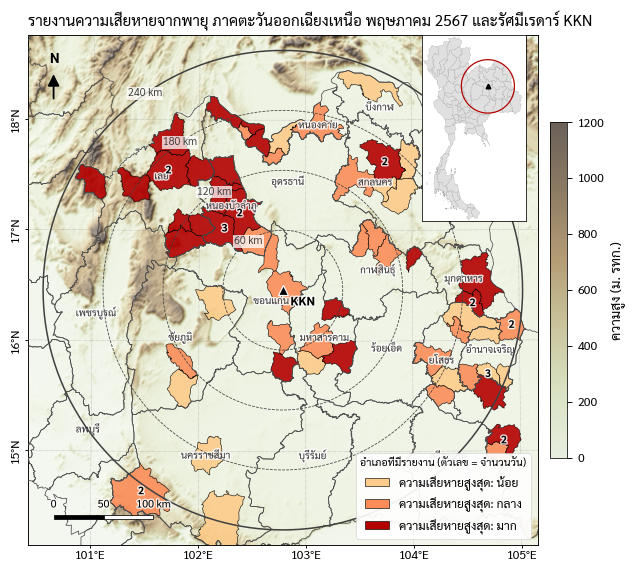

In [ ]:
order = {"น้อย": 0, "กลาง": 1, "มาก": 2}
by_dist = (gdf.assign(tier_n=gdf["tier"].map(order).astype(int))
              .dissolve(by=["pro_th", "amp_th"], aggfunc={"tier_n": "max", "report_id": "count"})
              .rename(columns={"report_id": "n_days"}).reset_index())
by_dist["tier"] = by_dist["tier_n"].map({v: k for k, v in order.items()})

fig, ax = plt.subplots(figsize=(7.2, 7.2))
M.base_map(ax, s, dem=dem)
for t, col in M.TIER_COLORS.items():
    sub = by_dist[by_dist["tier"] == t]
    if len(sub):
        M.plot_km(sub, ax, color=col, edgecolor="k", lw=0.4, alpha=0.9, zorder=8)
for _, r in by_dist[by_dist["n_days"] > 1].iterrows():
    p = r.geometry.representative_point()
    if abs(p.x) < 250e3 and abs(p.y) < 250e3 and np.hypot(p.x, p.y) > 15e3:   # ไม่ทับสัญลักษณ์เรดาร์
        ax.text(p.x / 1e3, p.y / 1e3, str(r.n_days), fontsize=7, fontweight="bold", ha="center", va="center",
                zorder=15, path_effects=M.HALO)
handles = [plt.Rectangle((0, 0), 1, 1, fc=c, ec="k", lw=0.4) for c in M.TIER_COLORS.values()]
leg = ax.legend(handles, [f"ความเสียหายสูงสุด: {t}" for t in M.TIER_COLORS], loc="lower right", frameon=True,
                title="อำเภอที่มีรายงาน (ตัวเลข = จำนวนวัน)", title_fontsize=7, framealpha=0.92)
leg.get_frame().set_linewidth(0.4); leg.set_zorder(50)
M.add_locator_inset(ax, s)
if dem[0] is not None:
    M.terrain_colorbar(fig, ax)
ax.set_title("รายงานความเสียหายจากพายุ ภาคตะวันออกเฉียงเหนือ พฤษภาคม 2567 และรัศมีเรดาร์ KKN", loc="left")
M.savefig(fig, "nb01_fig1_study_area")
plt.show()

### 7.2 ลำดับเวลารายวัน: จำนวนรายงานแยกระดับ และบ้านเสียหาย

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb01_fig2_timeline.png / .pdf


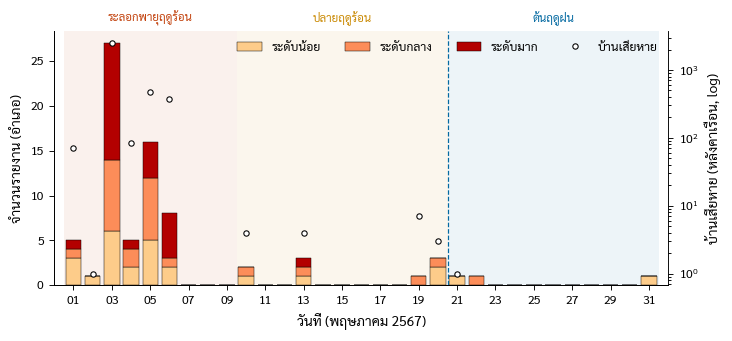

In [ ]:
cnt = gdf.groupby(["date", "tier"], observed=False).size().unstack(fill_value=0).reindex(may, fill_value=0)
hs = gdf.groupby("date")["houses"].sum(min_count=1).reindex(may)

fig, ax = plt.subplots(figsize=(7.2, 3.0))
for p in s["phases"]:
    a, b = pd.Timestamp(p["start"]), pd.Timestamp(p["end"]) + pd.Timedelta(days=1)
    ax.axvspan(a - pd.Timedelta(hours=12), b - pd.Timedelta(hours=12), color=M.PHASE_COLORS[p["key"]], alpha=0.07, lw=0)
    ax.text(a + (b - a) / 2 - pd.Timedelta(hours=12), 1.02, p["label_th"], transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=7.5, color=M.PHASE_COLORS[p["key"]])
bottom = np.zeros(len(may))
for t, col in M.TIER_COLORS.items():
    ax.bar(may, cnt[t].values, bottom=bottom, color=col, ec="k", lw=0.3, width=0.8, label=t)
    bottom += cnt[t].values
ax.axvline(pd.Timestamp("2024-05-21") - pd.Timedelta(hours=12), color="#0369a1", lw=0.8, ls="--")
ax.set_ylabel("จำนวนรายงาน (อำเภอ)")
ax2 = ax.twinx()
ax2.plot(may, hs.values, "o", ms=3.5, mfc="white", mec="k", mew=0.7, label="บ้านเสียหาย")
ax2.set_yscale("log"); ax2.set_ylabel("บ้านเสียหาย (หลังคาเรือน, log)")
ax2.spines["right"].set_visible(True)
ax.set_xlim(may[0] - pd.Timedelta(days=1), may[-1] + pd.Timedelta(days=1))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d"))
ax.set_xlabel("วันที่ (พฤษภาคม 2567)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, [f"ระดับ{x}" for x in l1] + l2, loc="upper right", frameon=False, ncol=4)
M.savefig(fig, "nb01_fig2_timeline")
plt.show()

### 7.3 วัฏจักรรายวัน: รายงานเกิดตอนไหนของวัน

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb01_fig3_diurnal.png / .pdf


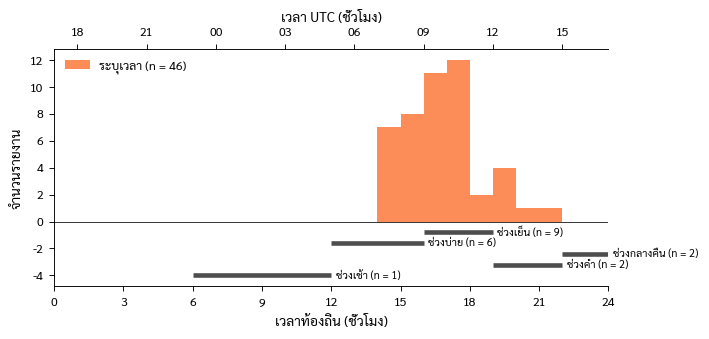

In [ ]:
ex = gdf[gdf.time_kind == "exact"]
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.hist(ex["t_report_h"], bins=np.arange(0, 25, 1), color="#fc8d59", ec="k", lw=0.4,
        label=f"ระบุเวลา (n = {len(ex)})")
per = gdf[gdf.time_kind == "period"]
for i, (k, v) in enumerate(per["t_start_raw"].value_counts().items()):
    a, b = s["reports"]["period_windows_local"][k]
    ax.hlines(-0.8 - 0.8 * i, a, min(b, 24), color="0.3", lw=3)
    ax.text(min(b, 24) + 0.2, -0.8 - 0.8 * i, f"{k} (n = {v})", va="center", fontsize=7)
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("เวลาท้องถิ่น (ชั่วโมง)"); ax.set_ylabel("จำนวนรายงาน")
top = ax.secondary_xaxis("top")
top.set_xticks(range(1, 25, 3), [f"{(h - 7) % 24:02d}" for h in range(1, 25, 3)])
top.set_xlabel("เวลา UTC (ชั่วโมง)")
ax.axhline(0, color="k", lw=0.5)
ax.set_ylim(-0.8 * (len(per["t_start_raw"].unique()) + 1), None)
ax.legend(frameon=False, loc="upper left")
M.savefig(fig, "nb01_fig3_diurnal")
plt.show()

### 7.4 แผนที่ชุด (small multiples) รายวัน

บันทึกรูป → /content/Teach_stormTracks_KKN_May2024_HID_doppler/figures/nb01_fig4_daily_maps.png / .pdf


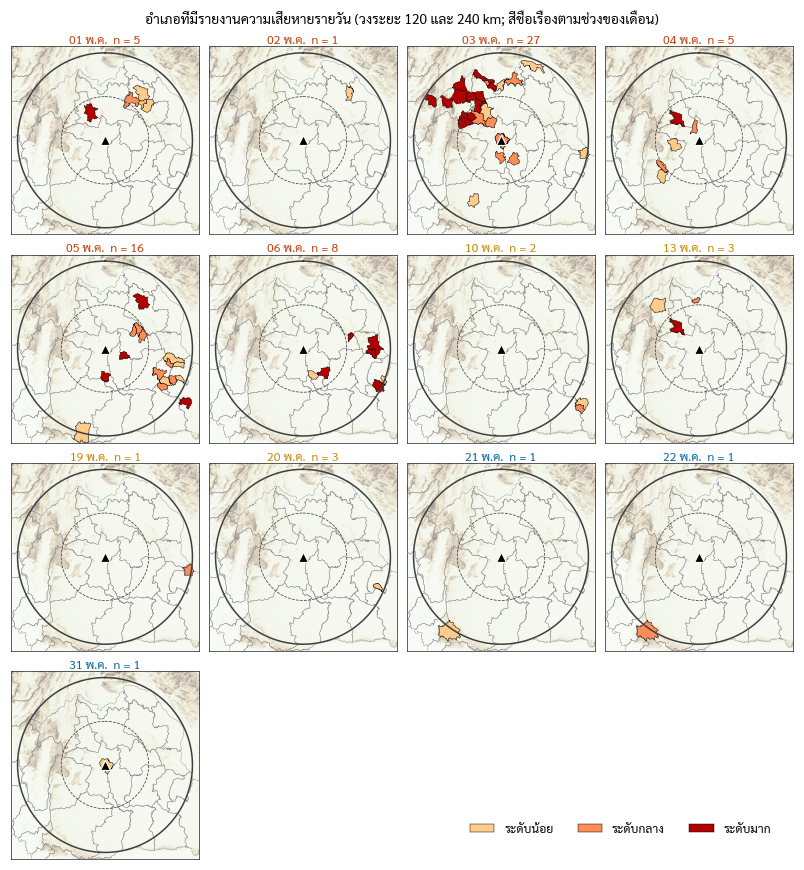

In [ ]:
days = sorted(gdf["date"].unique())
ncol = 4; nrow = int(np.ceil(len(days) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(7.2, 1.95 * nrow), constrained_layout=True)
prov = G.load_admin("province", s)
for ax, d in zip(axes.flat, days):
    g = gdf[gdf["date"] == d]
    M.add_hillshade(ax, dem[0], dem[1], alpha=0.55)
    M.plot_km(prov, ax, facecolor="none", edgecolor="0.55", lw=0.25, zorder=3)
    for t, col in M.TIER_COLORS.items():
        sub = g[g["tier"] == t]
        if len(sub):
            M.plot_km(sub, ax, color=col, edgecolor="k", lw=0.3, zorder=8)
    M.add_range_rings(ax, s, rings_km=[120, 240], label=False, name=False)
    ax.set_xlim(-258, 258); ax.set_ylim(-258, 258); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_linewidth(0.4)
    ph = g["phase"].iloc[0]
    ax.set_title(f"{pd.Timestamp(d):%d} พ.ค.  n = {len(g)}", fontsize=8, color=M.PHASE_COLORS[ph], pad=2)
for ax in axes.flat[len(days):]:
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, fc=c, ec="k", lw=0.3) for c in M.TIER_COLORS.values()]
fig.legend(handles, [f"ระดับ{t}" for t in M.TIER_COLORS], loc="lower right", ncol=3, frameon=False,
           bbox_to_anchor=(0.98, 0.02))
fig.suptitle("อำเภอที่มีรายงานความเสียหายรายวัน (วงระยะ 120 และ 240 km; สีชื่อเรื่องตามช่วงของเดือน)", fontsize=9)
M.savefig(fig, "nb01_fig4_daily_maps")
plt.show()

## 8. บันทึกผลลัพธ์สำหรับบทต่อไป

| ไฟล์ | เนื้อหา | ใช้ในบท |
|---|---|---|
| `data/reports/reports_may2024_clean.csv` | รายงานรายอำเภอ-วัน พร้อมเวลา UTC ระยะ ความสูงลำคลื่น ระดับความรุนแรง | 05, 06 |
| `data/reports/reports_may2024.gpkg` | ตารางเดียวกันพร้อม polygon อำเภอ (WGS84) | 05, 06, QGIS |
| `data/reports/days_may2024.csv` | สรุปรายวันและลำดับความสำคัญ | 02–06 |

In [ ]:
out = repo_path("data", "reports"); out.mkdir(parents=True, exist_ok=True)
keep = ["report_id", "date", "phase", "province", "district", "pro_code", "amp_code", "t_start_raw", "t_end_raw",
        "time_kind", "t_report_local", "t_report_utc", "win_start_utc", "win_end_utc",
        "wind", "hail", "hail_size", "lightning", "flood", "n_tambon", "n_village", "houses", "injured", "dead",
        "casualties", "S", "tier", "r_km", "az_deg", "r_min_km", "r_max_km", "frac_in_240", "coverage",
        "range_bin", "beam_h_km", "beam_w_km", "elev_mean_m", "elev_max_m", "in_range",
        "n_scans_in_window", "radar_verifiable", "note"]
tab = gdf[keep].copy()
tab["tier"] = tab["tier"].astype(str); tab["range_bin"] = tab["range_bin"].astype(str)
tab.to_csv(out / "reports_may2024_clean.csv", index=False, encoding="utf-8-sig")
gpd.GeoDataFrame(tab, geometry=gdf.geometry, crs=gdf.crs).to_crs(4326).to_file(out / "reports_may2024.gpkg", driver="GPKG")
d_out = day.copy(); d_out["day_tier"] = d_out["day_tier"].astype(str)
d_out.to_csv(out / "days_may2024.csv", encoding="utf-8-sig")
print("บันทึกแล้ว:", *sorted(p.name for p in out.iterdir()), sep="\n  ")

บันทึกแล้ว:
  days_may2024.csv
  reports_may2024.gpkg
  reports_may2024_clean.csv


## 9. แบบฝึกหัด

**ข้อ 1 — ระยะกับสิ่งที่เรดาร์เห็นได้** สร้างตารางไขว้จำนวนรายงานและบ้านเสียหายรวม แยกตามกลุ่มระยะ (`range_bin`) × ช่วงของเดือน (`phase`) แล้วคำนวณความสูงลำคลื่นเฉลี่ยในแต่ละกลุ่มระยะ อธิบายว่าการตีความลายเซ็นลมกระโชก (ΔV ใกล้พื้น) ของรายงานในกลุ่ม 160–240 km ต่างจากกลุ่ม 0–100 km อย่างไร

In [ ]:
# เขียนโค้ดของตนเองที่นี่

In [ ]:
# @title เฉลยข้อ 1 (ดับเบิลคลิกเพื่อดูโค้ด)
tab1 = gdf.pivot_table(index="range_bin", columns="phase", values="houses",
                       aggfunc=["count", "sum"], observed=False).fillna(0).astype(int)
display(tab1)
print(gdf.groupby("range_bin", observed=False)[["beam_h_km", "beam_w_km"]].mean().round(2))
# ตีความ: ที่ 160–240 km ลำคลื่นต่ำสุดอยู่สูง ~2.5–4 km และกว้าง ~3–4 km ลมกระโชกที่เกิดใต้ 1 km จึงมองไม่เห็นโดยตรง
# ต้องอาศัยตัวแทนในระดับสูง เช่น แกนการสะท้อนสูงที่ทรุดตัว หรือ convergence ระดับกลาง

count                     sum               
phase     late_pre outbreak rainy late_pre outbreak rainy
range_bin                                                
0–100            1       15     1        4      227     0
100–160          0       12     0        0     2511     0
160–240          4       23     0        9      788     0
>240             3        0     1        5        0     1

           beam_h_km  beam_w_km
range_bin                      
0–100           0.99       1.01
100–160         2.36       2.27
160–240         4.20       3.41
>240            6.92       4.72


**ข้อ 2 — ความถี่หรือความเข้ม?** คะแนนวัน $D=\sum S_i$ ผสม "จำนวนรายงาน" กับ "ความรุนแรงต่อรายงาน" เข้าด้วยกัน ให้คำนวณคะแนนแบบค่าเฉลี่ย $\bar{S}$ ต่อวัน (เฉพาะรายงานในรัศมี) แล้วหาสหสัมพันธ์สเปียร์แมนระหว่างอันดับวันจาก $D$ กับจาก $\bar{S}$ วันใดเปลี่ยนอันดับมากที่สุด และงานวิจัยแบบใดควรใช้คะแนนแบบไหน

In [ ]:
# เขียนโค้ดของตนเองที่นี่

In [ ]:
# @title เฉลยข้อ 2
ins = gdf[gdf["in_range"]]
S_mean = ins.groupby("date")["S"].mean().reindex(day.index)
cmp_ = pd.DataFrame({"D_ผลรวม": day["D_in_range"], "S_เฉลี่ย": S_mean, "n": day["n_in_range"]})
cmp_["อันดับ_D"] = cmp_["D_ผลรวม"].rank(ascending=False, method="min")
cmp_["อันดับ_S̄"] = cmp_["S_เฉลี่ย"].rank(ascending=False, method="min")
cmp_["เปลี่ยน"] = cmp_["อันดับ_S̄"] - cmp_["อันดับ_D"]
ok = cmp_["S_เฉลี่ย"].notna()
rho_, p_ = spearmanr(cmp_.loc[ok, "D_ผลรวม"], cmp_.loc[ok, "S_เฉลี่ย"])
print(f"Spearman ρ = {rho_:.2f} (p = {p_:.3f}, n = {ok.sum()} วัน)")
# ตีความ: วันที่มีรายงานน้อยแต่รุนแรง (เช่น อำเภอเดียวมีผู้เสียชีวิต) อันดับขึ้นมากเมื่อใช้ค่าเฉลี่ย
# งานด้าน "ภัยพิบัติรวมของวัน" ควรใช้ผลรวม ส่วนงาน "ลักษณะพายุที่ทำให้เสียหายรุนแรง" ควรใช้ค่าเฉลี่ยหรือค่าสูงสุด
cmp_.sort_values("อันดับ_S̄").round(2)

Spearman ρ = 0.66 (p = 0.021, n = 12 วัน)


,D_ผลรวม,S_เฉลี่ย,n,อันดับ_D,อันดับ_S̄,เปลี่ยน
date,,,,,,
2024-05-22,0.57,0.57,1,8.0,1.0,-7.0
2024-05-03,15.31,0.57,27,1.0,2.0,1.0
2024-05-06,4.49,0.56,8,3.0,3.0,0.0
2024-05-05,7.64,0.51,15,2.0,4.0,2.0
2024-05-19,0.49,0.49,1,9.0,5.0,-4.0
2024-05-13,1.46,0.49,3,6.0,6.0,0.0
2024-05-01,2.41,0.48,5,4.0,7.0,3.0
2024-05-04,2.35,0.47,5,5.0,8.0,3.0
2024-05-20,0.71,0.36,2,7.0,9.0,2.0


**ข้อ 3 — แผนที่ choropleth** สร้างแผนที่ระดับอำเภอของ **บ้านเสียหายรวมทั้งเดือนต่อพื้นที่ 100 km²** เฉพาะอำเภอที่อยู่ในรัศมี 240 km (ทั้งอำเภอหรือบางส่วน) ใช้ `M.base_map` และ colormap แบบลำดับ (sequential) พร้อม colorbar ที่มีหน่วย

In [ ]:
# เขียนโค้ดของตนเองที่นี่

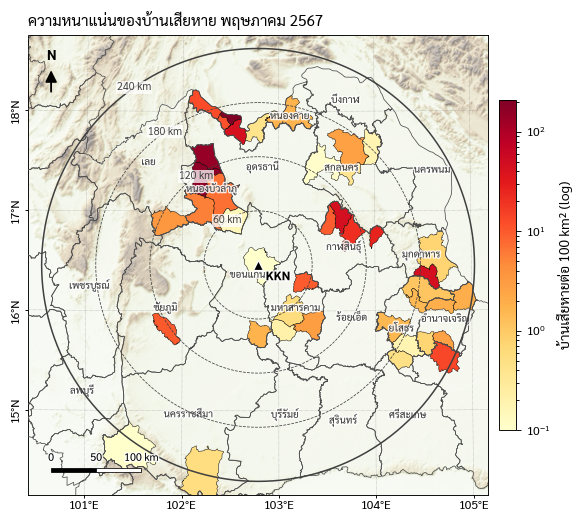

In [ ]:
# @title เฉลยข้อ 3
import matplotlib as mpl
dd = (gdf[gdf["in_range"]].dissolve(by=["pro_th", "amp_th"], aggfunc={"houses": "sum"}).reset_index())
dd["dens"] = dd["houses"] / (dd.geometry.area / 1e6) * 100
fig, ax = plt.subplots(figsize=(6.5, 6.5))
M.base_map(ax, s, dem=dem, dem_alpha=0.6)
norm = mpl.colors.LogNorm(vmin=max(dd["dens"][dd["dens"] > 0].min(), 0.1), vmax=dd["dens"].max())
M.plot_km(dd[dd["dens"] > 0], ax, column="dens", cmap="YlOrRd", norm=norm, edgecolor="k", lw=0.3, zorder=8)
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap="YlOrRd"), ax=ax, shrink=0.6, pad=0.02)
cb.set_label("บ้านเสียหายต่อ 100 km² (log)")
ax.set_title("ความหนาแน่นของบ้านเสียหาย พฤษภาคม 2567", loc="left")
plt.show()

## 10. คำถามชวนคิด

1. ถ้าอำเภอ A มีบ้านเสียหาย 500 หลังและอำเภอ B มี 5 หลัง เราสรุปได้หรือไม่ว่าพายุที่ A แรงกว่า? ควรใช้ข้อมูลอะไรเพิ่ม (จำนวนครัวเรือน ประเภทหลังคา ความหนาแน่นประชากร) เพื่อแยก "ความรุนแรงของพายุ" ออกจาก "ความเปราะบางของพื้นที่"
2. รายงานหลังวันที่ 10 พ.ค. ลดลงมาก เป็นเพราะพายุลดลงจริง พายุเปลี่ยนลักษณะ (เช่น ฝนแบบ stratiform มากขึ้น ลมกระโชกน้อยลง) หรือความสนใจของสื่อลดลง? บท 02 จะตอบด้วยข้อมูลเรดาร์
3. หน้าต่างเวลา ±60 นาทีเหมาะหรือไม่? ถ้ากว้างไป จะจับคู่รายงานกับพายุผิดลูก ถ้าแคบไปอาจไม่พบพายุเลย จะทดสอบความไวของการเลือกนี้อย่างไร
4. รายงานในกลุ่มระยะ > 240 km ยังมีประโยชน์ต่องานวิจัยหรือไม่ ถ้ามีเรดาร์ข้างเคียง (เช่น อุบลราชธานี) จะออกแบบการรวมข้อมูลหลายเรดาร์อย่างไร

## 11. แนวทางต่อยอดงานวิจัย

- ปรับดัชนีความรุนแรงเป็น **ความเสียหายต่อครัวเรือน** โดยใช้ข้อมูลทะเบียนบ้านระดับอำเภอ/ตำบล (กรมการปกครอง) เพื่อลด exposure bias
- รวมฐานข้อมูลหลายปี (ไฟล์นี้มีข้อมูล 2566–2568 บางเดือน) เพื่อหาภูมิอากาศวิทยาของพายุฤดูร้อนรายอำเภอ
- จับคู่รายงานกับข้อมูลฟ้าผ่าจากเครือข่ายตรวจวัดภาคพื้นดิน เพื่อยืนยันเวลาเกิดพายุที่แม่นยำกว่าความจำของผู้รายงาน
- ใช้การประมวลผลภาษาธรรมชาติกับคอลัมน์ `หมายเหตุ` เพื่อสกัดชนิดความเสียหาย (หลังคาปลิว ต้นไม้ล้ม เสาไฟฟ้าล้ม) เป็นตัวแทนความเร็วลม

## เอกสารอ้างอิง

- Doviak, R. J., & Zrnić, D. S. (1993). *Doppler Radar and Weather Observations* (2nd ed.). Academic Press.
- Rinehart, R. E. (2004). *Radar for Meteorologists* (4th ed.). Rinehart Publications.
- European Space Agency (2021). *Copernicus Global Digital Elevation Model (GLO-90)*. https://doi.org/10.5270/ESA-c5d3d65
- OpenGISData-Thailand (chingchai). ขอบเขตการปกครองประเทศไทย, CC BY 4.0. https://github.com/chingchai/OpenGISData-Thailand
- กรมอุตุนิยมวิทยา (2567). ประกาศเข้าสู่ฤดูฝน 21 พฤษภาคม 2567

In [ ]:
# @title 🔒 (เฉพาะผู้ดูแลข้อมูล) เก็บผลบทนี้ (data/reports, DEM) เข้า Drive และ commit — นิสิตข้ามได้
if ADMIN_SYNC:
    sync.push(OUT_ROOT)
    COMMIT = False
    if COMMIT:
        sync.git_push("NB01: cleaned reports, day table, DEM 1 km", dry_run=False)

sync.push: /content/Teach_stormTracks_KKN_May2024_HID_doppler → /content/drive/MyDrive/000_research/08Storm_NorthEast_FF69/0data/1radar/KKN_derived_v1/repo_mirror
  คัดลอก 3 ไฟล์ (0.5 MB): data/reports/days_may2024.csv, data/reports/reports_may2024.gpkg, data/reports/reports_may2024_clean.csv
